In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
import pandas as pd

df = pd.read_csv("2025-fairness-recruitment-dataset.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [12]:
# Load dataset
df = pd.read_csv("2025-fairness-recruitment-dataset.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Display available columns
print("Available columns:")
print(df.columns.tolist())

print("\nFirst five rows:")
print(df.head())

Available columns:
['mainid(hidden)', 'mod15(hidden)', 'div15(hidden)', 'Age(feature, sensitive))', 'Speed(hidden)', 'Gender(feature,sensitive)', 'Strength(hidden)', 'Speedtest(hidden)', 'Lifttest(hidden)', 'testresult(feature)', 'livesnear(feature)', 'Suitability(target)', 'Value-when-hired(hidden)', 'Candidate-loss-when-nothired(hidden)', 'Should-hire(target)', 'Shouldnothire', 'hired-by-expert', 'A1(testresult)', 'A2(testresult,30under)', 'A3(Age,Gender, test)', 'A4(postive-dicr)']

First five rows:
   mainid(hidden)  mod15(hidden)  div15(hidden)  Age(feature, sensitive))  \
0          225000              0              0                        22   
1          225001              1              0                        26   
2          225002              2              0                        28   
3          225003              3              0                        28   
4          225004              4              0                        32   

   Speed(hidden) Gender(featu

In [13]:
# Keep only necessary columns
df = df[[
    "Age(feature, sensitive))",
    "Gender(feature,sensitive)",
    "testresult(feature)",
    "Should-hire(target)"
]]

# Rename columns
df = df.rename(columns={
    "Age(feature, sensitive))": "age",
    "Gender(feature,sensitive)": "gender",
    "testresult(feature)": "test_result",
    "Should-hire(target)": "hired"
})

In [14]:
# Convert target to integer
df["hired"] = df["hired"].astype(int)

# Display dataset information
print("\nDataset Information:")
print(df.info())

print("\nClass Distribution:")
print(df["hired"].value_counts())

# Create age groups
def age_group(age):
    if age < 25:
        return "<25"
    elif age <= 35:
        return "25-35"
    else:
        return "35+"

df["age_group"] = df["age"].apply(age_group)

print("\nAge Group Distribution:")
print(df["age_group"].value_counts())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          225 non-null    int64  
 1   gender       225 non-null    str    
 2   test_result  225 non-null    float64
 3   hired        225 non-null    int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 7.2 KB
None

Class Distribution:
hired
0    150
1     75
Name: count, dtype: int64

Age Group Distribution:
age_group
35+      122
25-35     71
<25       32
Name: count, dtype: int64


In [16]:
from sklearn.model_selection import train_test_split

In [17]:
# Select features and target
X = df[["age", "gender", "test_result"]].copy()
y = df["hired"].copy()

# Convert features to strings for categorical ID3
for col in X.columns:
    X[col] = X[col].astype(str)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (157, 3)
Testing data shape: (68, 3)


In [18]:
def entropy(y):
    y = np.array(y)

    unique_values = np.unique(y)

    counts = [
        np.sum(y == value)
        for value in unique_values
    ]

    probabilities = np.array(counts) / len(y)

    return -np.sum([
        p * np.log2(p)
        for p in probabilities
        if p > 0
    ])

In [19]:
def information_gain(X_column, y):

    parent_entropy = entropy(y)

    values = np.unique(X_column)

    weighted_entropy = 0

    for value in values:

        subset_y = y[X_column == value]

        weighted_entropy += (
            len(subset_y) / len(y)
        ) * entropy(subset_y)

    return parent_entropy - weighted_entropy

In [20]:
def id3(
    X,
    y,
    depth=0,
    max_depth=5,
    min_samples=5
):

    # Stop if all target values are the same
    if len(np.unique(y)) == 1:
        return y.iloc[0]

    # Stop if no features remain
    if len(X.columns) == 0:
        return Counter(y).most_common(1)[0][0]

    # Stop if depth or minimum sample limit is reached
    if depth >= max_depth or len(y) < min_samples:
        return Counter(y).most_common(1)[0][0]

    # Calculate information gain for each feature
    gains = [
        information_gain(X[col], y)
        for col in X.columns
    ]

    # Select the feature with maximum gain
    best_feature = X.columns[np.argmax(gains)]

    tree = {
        best_feature: {}
    }

    # Create branches
    for value in np.unique(X[best_feature]):

        mask = X[best_feature] == value

        subset_X = X[mask].drop(
            columns=[best_feature]
        )

        subset_y = y[mask]

        subtree = id3(
            subset_X,
            subset_y,
            depth + 1,
            max_depth,
            min_samples
        )

        tree[best_feature][value] = subtree

    return tree

In [22]:
from collections import Counter

In [23]:
tree = id3(
    X_train,
    y_train,
    max_depth=5,
    min_samples=5
)

print("\nTrained Decision Tree:")
print(tree)


Trained Decision Tree:
{'test_result': {'0.0': np.int64(0), '0.5': np.int64(0), '1.0': {'age': {'21': np.int64(0), '22': 1, '23': np.int64(0), '24': 1, '25': np.int64(1), '26': 1, '29': 1, '30': np.int64(0), '31': np.int64(0), '32': np.int64(0), '33': np.int64(1), '35': 0, '36': np.int64(0), '37': np.int64(0), '38': np.int64(0), '39': np.int64(0), '40': np.int64(0), '41': np.int64(0), '42': np.int64(0), '43': np.int64(0), '44': np.int64(0), '46': 0, '47': np.int64(0), '48': 0, '49': np.int64(0)}}, '1.5': {'age': {'20': np.int64(1), '21': np.int64(1), '22': np.int64(0), '23': np.int64(1), '24': np.int64(1), '25': np.int64(1), '26': 0, '27': np.int64(0), '28': 0, '29': np.int64(1), '30': np.int64(0), '31': np.int64(1), '33': 1, '34': np.int64(0), '35': np.int64(1), '36': {'gender': {'female': np.int64(1), 'male': 0}}, '38': 1, '39': np.int64(0), '40': 0, '41': np.int64(1), '42': 0, '43': np.int64(0), '44': 0, '45': np.int64(0), '46': np.int64(1), '47': np.int64(0), '48': np.int64(0), '4

In [24]:
def predict(sample, tree):

    # If tree is a leaf, return the prediction
    if not isinstance(tree, dict):
        return tree

    # Get the feature used for splitting
    feature = list(tree.keys())[0]

    value = sample.get(feature)

    # Follow the matching branch
    if value in tree[feature]:
        return predict(
            sample,
            tree[feature][value]
        )

    # Default prediction for unseen values
    return 0


def predict_dataset(X, tree):

    return X.apply(
        lambda row: predict(row, tree),
        axis=1
    )


y_pred = predict_dataset(
    X_test,
    tree
)

print("\nPredictions completed!")
print(y_pred.head())


Predictions completed!
191    0
112    0
196    1
172    0
34     1
dtype: int64


In [25]:
TP = sum(
    (y_test == 1) & (y_pred == 1)
)

TN = sum(
    (y_test == 0) & (y_pred == 0)
)

FP = sum(
    (y_test == 0) & (y_pred == 1)
)

FN = sum(
    (y_test == 1) & (y_pred == 0)
)

accuracy = (
    (TP + TN) / len(y_test)
)

precision = (
    TP / (TP + FP)
    if (TP + FP) != 0
    else 0
)

recall = (
    TP / (TP + FN)
    if (TP + FN) != 0
    else 0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) != 0
    else 0
)

print("\n========== PERFORMANCE METRICS ==========")

print("True Positives:", TP)
print("True Negatives:", TN)
print("False Positives:", FP)
print("False Negatives:", FN)

print("\nAccuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)


========== PERFORMANCE METRICS ==========
True Positives: 9
True Negatives: 41
False Positives: 4
False Negatives: 14

Accuracy: 0.7352941176470589
Precision: 0.6923076923076923
Recall: 0.391304347826087
F1-score: 0.5


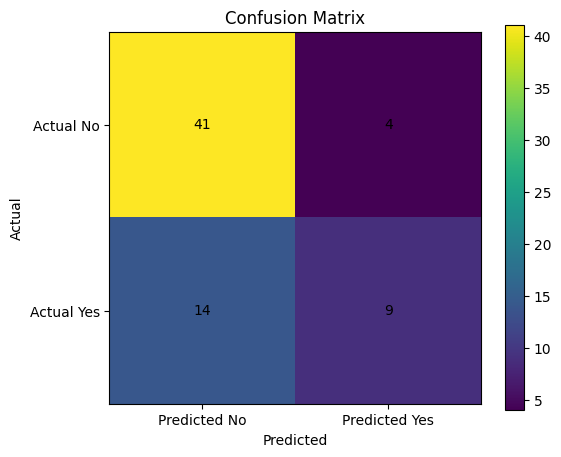

In [26]:
conf_matrix = np.array([
    [TN, FP],
    [FN, TP]
])

plt.figure(figsize=(6, 5))

plt.imshow(conf_matrix)

plt.title("Confusion Matrix")

plt.xticks(
    [0, 1],
    ["Predicted No", "Predicted Yes"]
)

plt.yticks(
    [0, 1],
    ["Actual No", "Actual Yes"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            conf_matrix[i, j],
            ha="center",
            va="center"
        )

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.show()

In [27]:
def calculate_feature_importance(X, y):

    importance = {}

    for col in X.columns:

        importance[col] = information_gain(
            X[col],
            y
        )

    return sorted(
        importance.items(),
        key=lambda x: x[1],
        reverse=True
    )


importance = calculate_feature_importance(
    X_train,
    y_train
)

print("\n========== FEATURE IMPORTANCE ==========")

for feature, score in importance:
    print(
        feature,
        ":",
        round(score, 6)
    )


========== FEATURE IMPORTANCE ==========
test_result : 0.245486
age : 0.215256
gender : 0.022754


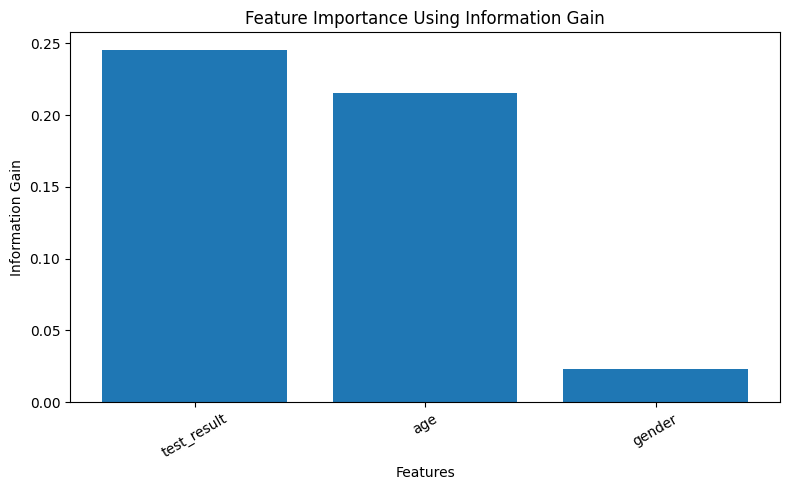

In [28]:
features = [
    item[0]
    for item in importance
]

scores = [
    item[1]
    for item in importance
]

plt.figure(figsize=(8, 5))

plt.bar(features, scores)

plt.title("Feature Importance Using Information Gain")
plt.xlabel("Features")
plt.ylabel("Information Gain")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [29]:
test_df = X_test.copy()

test_df["actual"] = y_test
test_df["predicted"] = y_pred

# Add original demographic information
test_df["gender"] = df.loc[
    X_test.index,
    "gender"
]

test_df["age_group"] = df.loc[
    X_test.index,
    "age_group"
]

print("\nFairness analysis data:")
print(test_df.head())


Fairness analysis data:
    age  gender test_result  actual  predicted age_group
191  45  female         1.0       0          0       35+
112  39    male         1.0       0          0       35+
196  25  female         1.0       0          1     25-35
172  32  female         1.0       0          0     25-35
34   32    male         2.0       1          1     25-35


In [30]:
print("\n========== DEMOGRAPHIC PARITY: GENDER ==========")

for group in sorted(
    test_df["gender"].dropna().unique()
):

    group_data = test_df[
        test_df["gender"] == group
    ]

    hiring_rate = (
        group_data["predicted"] == 1
    ).mean()

    print(
        group,
        "Hiring Rate:",
        round(hiring_rate, 4)
    )


========== DEMOGRAPHIC PARITY: GENDER ==========
female Hiring Rate: 0.1852
male Hiring Rate: 0.1951


In [31]:
print("\n========== DEMOGRAPHIC PARITY: AGE ==========")

for group in ["<25", "25-35", "35+"]:

    group_data = test_df[
        test_df["age_group"] == group
    ]

    if len(group_data) == 0:
        print(group, "No data available")
        continue

    hiring_rate = (
        group_data["predicted"] == 1
    ).mean()

    print(
        group,
        "Hiring Rate:",
        round(hiring_rate, 4)
    )


========== DEMOGRAPHIC PARITY: AGE ==========
<25 Hiring Rate: 0.8333
25-35 Hiring Rate: 0.2857
35+ Hiring Rate: 0.0488


In [33]:
print("\n========== EQUAL OPPORTUNITY: AGE ==========")

for group in ["<25", "25-35", "35+"]:

    group_data = test_df[
        test_df["age_group"] == group
    ]

    TP_group = sum(
        (group_data["actual"] == 1) &
        (group_data["predicted"] == 1)
    )

    FN_group = sum(
        (group_data["actual"] == 1) &
        (group_data["predicted"] == 0)
    )

    tpr = (
        TP_group / (TP_group + FN_group)
        if (TP_group + FN_group) != 0
        else np.nan
    )

    print(
        group,
        "TPR:",
        round(tpr, 4)
        if not np.isnan(tpr)
        else "Not available"
    )


========== EQUAL OPPORTUNITY: AGE ==========
<25 TPR: 0.8333
25-35 TPR: 0.3333
35+ TPR: 0.125


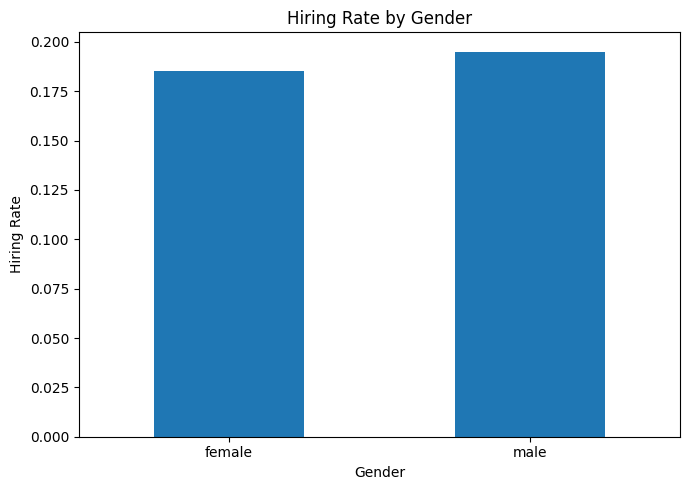

In [34]:
gender_rates = (
    test_df.groupby("gender")["predicted"]
    .apply(lambda x: (x == 1).mean())
)

plt.figure(figsize=(7, 5))

gender_rates.plot(kind="bar")

plt.title("Hiring Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Hiring Rate")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

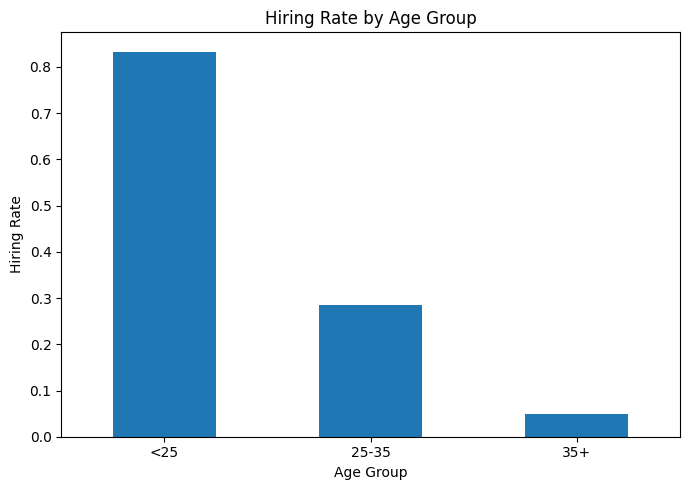

In [35]:
age_rates = (
    test_df.groupby("age_group")["predicted"]
    .apply(lambda x: (x == 1).mean())
)

plt.figure(figsize=(7, 5))

age_rates.reindex(
    ["<25", "25-35", "35+"]
).plot(kind="bar")

plt.title("Hiring Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Hiring Rate")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [36]:
depths = [2, 3, 5, 7, 10]

depth_accuracies = []

for depth in depths:

    depth_tree = id3(
        X_train,
        y_train,
        max_depth=depth,
        min_samples=5
    )

    depth_predictions = predict_dataset(
        X_test,
        depth_tree
    )

    depth_accuracy = (
        (y_test == depth_predictions).mean()
    )

    depth_accuracies.append(depth_accuracy)

    print(
        "Depth:",
        depth,
        "| Accuracy:",
        round(depth_accuracy, 4)
    )

Depth: 2 | Accuracy: 0.75
Depth: 3 | Accuracy: 0.7353
Depth: 5 | Accuracy: 0.7353
Depth: 7 | Accuracy: 0.7353
Depth: 10 | Accuracy: 0.7353


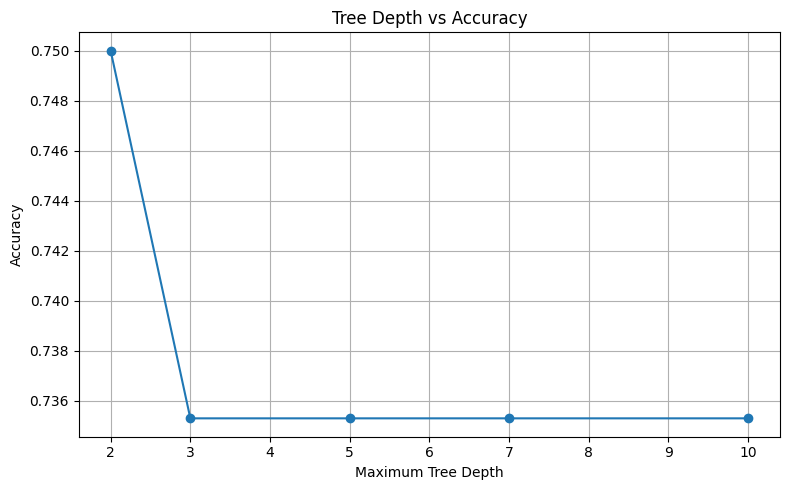

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    depths,
    depth_accuracies,
    marker="o"
)

plt.title("Tree Depth vs Accuracy")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")

plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
print("\n========== FINAL SUMMARY ==========")

print("Total dataset rows:", len(df))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nModel Metrics:")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))

print("\nMost important feature:")
print(importance[0][0])

print("\nTask completed!")


========== FINAL SUMMARY ==========
Total dataset rows: 225
Training rows: 157
Testing rows: 68

Model Metrics:
Accuracy: 0.7353
Precision: 0.6923
Recall: 0.3913
F1-score: 0.5

Most important feature:
test_result

Task completed!


# MARVEL Task 7: Fairness Meets Functionality

## Complete Explanation of the Project

In this task, I developed a Decision Tree machine learning model from scratch using the ID3 (Iterative Dichotomiser 3) algorithm. The purpose of the project was to predict whether a candidate should be hired based on recruitment-related features and evaluate the model's performance. I also explored feature importance and the importance of fairness when using machine learning in recruitment.

The model was trained using a recruitment dataset containing 225 records. The input features included age, gender, and test result, while the target variable was whether the candidate should be hired.

## 1. Dataset Loading and Preprocessing

First, I imported the necessary Python libraries, including:

* Pandas: To load and process the dataset.

* NumPy: To work with numerical values.

* Matplotlib and Seaborn: To create visualizations.

* Train-test split: To divide the dataset into training and testing data.

* Counter: To identify the most common class during decision tree construction.

I loaded the recruitment dataset using Pandas and selected the relevant columns:

|
Feature

|

Description

|
| --- | --- |
|

`age`

|

Age of the candidate

|
|

`gender`

|

Gender of the candidate

|
|

`test_result`

|

Candidate's test result

|
|

`hired`

|

Target variable indicating whether the candidate should be hired

|

The target variable was converted into integer values:

* `0` → Not hired

* `1` → Hired

The features were converted into string values so that the ID3 algorithm could process them as categorical values.

### Why preprocessing was needed

Preprocessing helped organize the dataset into a format that could be used by the machine learning algorithm. It also ensured that the input features and target variable were separated correctly.

## 2. Dividing the Dataset into Training and Testing Data

The dataset contained 225 rows. I divided it into two parts:

|
Dataset

|

Number of rows

|
| --- | --- |
|

Training data

|

157

|
|

Testing data

|

68

|
|

Total

|

225

|

I used a 70:30 training-testing split with `random_state=42` and stratification.

### What is training data?

Training data is used by the machine learning algorithm to learn patterns from the dataset.

### What is testing data?

Testing data is used after training to check how well the model predicts results for data it has not seen during training.

The testing data was kept separate from the training process so that the model could be evaluated on unseen examples.

## 3. Understanding the ID3 Algorithm

I implemented the ID3 Decision Tree algorithm from scratch instead of directly using a ready-made decision tree model from a machine learning library.

ID3 builds a decision tree by selecting the feature that provides the highest information gain.

The main concepts used were:

1. Entropy

2. Information gain

3. Feature selection

4. Recursive tree construction

5. Prediction

## 4. Entropy

Entropy measures the uncertainty or impurity in the target data.

For example, if a group contains both hired and not-hired candidates, there is uncertainty about the target class.

The entropy formula is:

Entropy(S)=−∑pilog⁡2(pi)Entropy(S)=-\sum p_i\log_2(p_i)Entropy(S)=−∑pilog2(pi)

Here:

* pip_ipi is the probability of a particular class.

* Higher entropy indicates greater uncertainty.

* Lower entropy indicates that the data is more concentrated in one class.

### Why entropy was used

Entropy helped the algorithm determine how mixed the target values were before and after splitting the data.

## 5. Information Gain

Information gain measures how much uncertainty is reduced when a feature is used to split the dataset.

The formula is:

Information Gain=Entropy(parent)−Weighted Entropy(children)Information\ Gain = Entropy(parent) - Weighted\ Entropy(children)Information Gain=Entropy(parent)−Weighted Entropy(children)

The algorithm calculated the information gain for the available features and selected the feature with the highest value.

### Why information gain was important

It helped the decision tree choose the most useful feature at each stage of its construction.

## 6. Building the Decision Tree

The `id3()` function was used to construct the tree recursively.

The algorithm followed these steps:

1. Check whether all target values are the same.

2. Check whether the maximum tree depth has been reached.

3. Check whether the number of samples is below the minimum limit.

4. Calculate information gain for the available features.

5. Select the feature with the highest information gain.

6. Split the dataset according to the values of that feature.

7. Recursively build smaller branches.

8. Return the most common target value when further splitting is stopped.

I used the following parameters:

Python

Run

```
max_depth = 5
min_samples = 5
```

### Meaning of these parameters

* Maximum depth = 5: The tree can grow up to five levels.

* Minimum samples = 5: A node with fewer than five samples is not split further.

These limits help control the growth of the tree and can reduce excessive memorization of training data.

## 7. Training Result

After implementing the ID3 algorithm, I trained the model using:

Python

Run

```
tree = id3(
    X_train,
    y_train,
    max_depth=5,
    min_samples=5
)
```

The model successfully generated a decision tree.

The root feature of the tree was:

```
test_result
```

This means that `test_result` had the highest information gain for the first split of the training data.

The tree then used features such as `age` and, in some branches, `gender` to make further decisions.

### Example of the decision process

A simplified decision path could look like this:

```
Test Result
    |
    |-- 0.0  → Not hired
    |
    |-- 1.0  → Check age
    |
    |-- 1.5  → Check age
    |
    |-- 2.0  → Check age
```

Some branches used gender after checking the test result and age.

The actual tree contained multiple branches based on the values in the training dataset.

## 8. Making Predictions

After training, I used the decision tree to predict the target values for the testing dataset.

The prediction function followed the tree structure:

1. Start at the root feature.

2. Check the corresponding feature value in a test row.

3. Move to the matching branch.

4. Continue until a prediction is reached.

5. Return either `0` or `1`.

The predictions were stored in `y_pred` and compared with the actual testing labels, `y_test`.

## 9. Model Evaluation Results

The final output of my model was:

```
Total dataset rows: 225
Training rows: 157
Testing rows: 68

Accuracy: 0.7353
Precision: 0.6923
Recall: 0.3913
F1-score: 0.5

Most important feature: test_result
```

### Explanation of the results

|
Metric

|

Result

|

Explanation

|
| --- | --- | --- |
|

Accuracy

|

73.53%

|

The model correctly predicted approximately 73.53% of the testing samples.

|
|

Precision

|

69.23%

|

Of the candidates predicted as hired, approximately 69.23% were actually hired.

|
|

Recall

|

39.13%

|

The model identified approximately 39.13% of the candidates who were actually hired.

|
|

F1-score

|

0.50

|

This combines precision and recall into one measure.

|

### Accuracy

The model correctly classified approximately 73.53% of the 68 test samples.

### Precision

Precision indicates how reliable the model's positive predictions were. A precision of 69.23% means that many of the candidates predicted as hired were actually in the positive class.

### Recall

Recall was 39.13%. This means that the model identified only a portion of the candidates who actually belonged to the hired class. Some positive cases were missed.

### F1-score

The F1-score was 0.50. It considers both precision and recall, making it useful when we want to evaluate positive predictions without relying only on accuracy.

Important: These metrics describe the performance of this particular train-test split. They do not establish that the model is suitable for real-world recruitment.

## 10. Feature Importance

The most important feature identified by the model was:

```
test_result
```

This feature was selected as the root of the decision tree because it provided the highest information gain during the initial split.

The other features were:

* `age`

* `gender`

The tree also used these features in some branches.

### Interpretation

The model found that test result was the most useful feature for separating the target classes in the training data. However, this does not necessarily mean that test result is always the most important factor in real recruitment situations.

Feature importance depends on the dataset, the algorithm, and the way the data was prepared.

## 11. Fairness in Recruitment

The task was titled Fairness Meets Functionality because a machine learning model should not only make predictions but should also be examined for possible unfair treatment.

The dataset contains demographic features such as:

* Gender

* Age

These features require special consideration because recruitment decisions can affect people from different demographic groups.

### Demographic parity

Demographic parity compares the positive prediction rate between groups.

For example:

Selection Rate=Number of positive predictionsTotal number of candidates in the groupSelection\ Rate = \frac{\text{Number of positive predictions}}{\text{Total number of candidates in the group}}Selection Rate=Total number of candidates in the groupNumber of positive predictions

This helps determine whether different groups are receiving positive predictions at different rates.

### Equal opportunity

Equal opportunity compares the true positive rate between groups.

True Positive Rate=TPTP+FNTrue\ Positive\ Rate = \frac{TP}{TP+FN}True Positive Rate=TP+FNTP

It measures how often the model correctly identifies positive cases within each group.

### Why these measures matter

A model could have reasonable overall accuracy while still producing different outcomes for different demographic groups. Therefore, overall accuracy alone is not enough to evaluate fairness.

## 12. Responsible AI Considerations

The project also highlights several responsible AI concerns.

### 1. Use of demographic features

Age and gender were included in the model. These features may contribute to unequal outcomes, so their influence should be examined carefully.

### 2. Proxy variables

Even if a demographic feature is removed, another feature could indirectly represent it. Such features are called proxy variables.

### 3. Missing demographic information

If demographic information is missing or incorrectly recorded, fairness analysis may not accurately represent the different groups.

### 4. Overfitting

A decision tree that grows too deeply may memorize training examples instead of learning general patterns. Using `max_depth` and `min_samples` helps control the tree's complexity.

### 5. Human supervision

A recruitment model should not independently make final hiring decisions. Human review, transparency, validation, and appropriate safeguards are necessary.

### 6. Dataset limitations

The model was trained on only 225 records. This is a relatively small dataset for making conclusions about real recruitment processes. The results should therefore be treated as an educational experiment rather than proof of real-world performance.

## 13. Overall Workflow

The complete process followed in the project was:

1. Load the dataset

Clean and select columns

2. Preprocess the data

Separate inputs and target

3. Split into training and testing data

Calculate entropy and information gain

4. Build the ID3 decision tree

Use the trained tree on unseen data

5. Generate predictions

Compare predictions with actual labels

6. Evaluate accuracy, precision, recall, and F1-score

Study model decisions and possible unequal outcomes

7. Analyze feature importance and fairness

## 14. Final Conclusion

> In this task, I developed a Decision Tree model from scratch using the ID3 algorithm to predict recruitment outcomes. I preprocessed the dataset, divided it into training and testing sets, and used entropy and information gain to construct the decision tree. The model was trained on 157 records and tested on 68 records. It achieved an accuracy of 73.53%, precision of 69.23%, recall of 39.13%, and an F1-score of 0.50. The `test_result` feature was identified as the most important feature and was used as the root of the tree. The project helped me understand how machine learning models learn from data, make predictions, and are evaluated using different performance metrics. It also highlighted the importance of fairness, demographic analysis, responsible AI, and human supervision when applying machine learning to recruitment decisions.

In simple words: You provided recruitment data to the algorithm, the ID3 algorithm learned how different feature values were associated with the hiring target, built a decision tree using information gain, and then used that tree to predict outcomes for new test records. Finally, you measured how well those predictions matched the actual results and considered the fairness implications of using demographic features.
